# 02. Modular DETAW: Switching $ET_0$ Equations, Flexible Inputs & OpenET Integration

One of the primary design goals of the `xarray`/`pandas` DETAW rewrite (`deltacd.detaw`) is **modularity**. Researchers and engineers can swap individual modeling components without modifying core water-balance or channel-depletion code:

1. **Switch Reference $ET_0$ Equations**: Compare **Hargreaves–Samani** (`hargreaves_samani`) against **ASCE Standardized Penman–Monteith** (`asce_penman_monteith`).
2. **Use Precomputed / Gridded Meteorology (`DatasetMeteorologyProvider`)**: Drive subareas directly from spatial meteorology NetCDF/CSV datasets.
3. **Plug In External ET / OpenET (`ExternalETProvider`)**: Replace internal $K_c \times ET_0$ crop evapotranspiration with daily or monthly **OpenET** products while preserving DETAW's root-zone rainfall/seepage accounting and feeding **DCD** seamlessly.
4. **Order-Independent Inputs & Custom Crop Categories**: Supply CSV tables in any column/row order or register new land-use types declaratively.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import yaml

import deltacd.dcd
from deltacd.detaw import (
    DetawConfig,
    DetawModel,
    asce_penman_monteith,
    hargreaves_samani,
    read_weather_station_csv,
)

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
REPO_ROOT = Path("..").resolve() if Path("../examples").exists() else Path(".").resolve()

## 1. Switching Reference $ET_0$ Equations: Hargreaves–Samani vs. ASCE Penman–Monteith

When solar radiation ($R_s$), 2 m wind speed ($u_2$), and dew-point temperature ($T_d$) or relative humidity ($RH_{\max}, RH_{\min}$) are available (such as at CIMIS stations or climate reanalysis grids), DETAW can compute **ASCE Standardized Penman–Monteith** $ET_0$ directly via `meteorology.eto_method = "asce_penman_monteith"`.

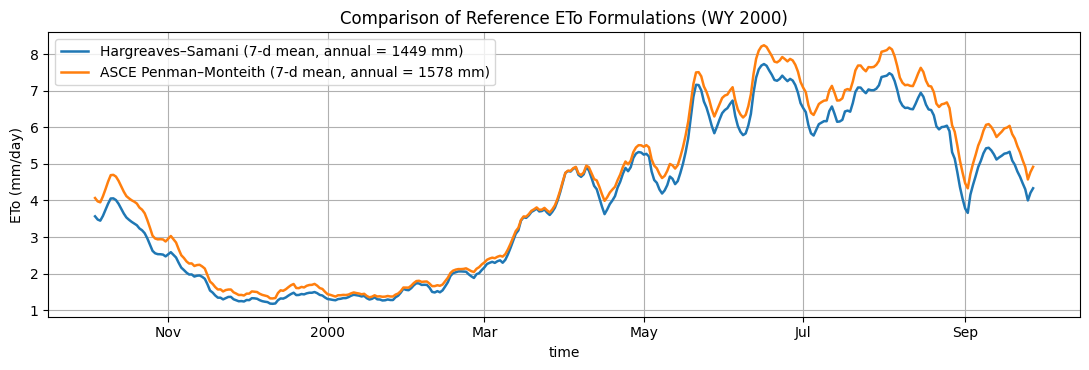

In [2]:
ds_wx = read_weather_station_csv(
    REPO_ROOT / "examples" / "inputs" / "PT_ex1.csv",
    start_date="1999-10-01",
    end_date="2000-09-30",
)
doy = ds_wx["time"].dt.dayofyear
ds_wx["solar_rad"] = (18.5 + 11.0 * np.sin(2 * np.pi * (doy - 80) / 365.0)).clip(min=4.0)
ds_wx["wind_speed"] = xr.DataArray(
    2.4 + 0.8 * np.sin(2 * np.pi * (doy - 110) / 365.0),
    dims=("time",),
    coords={"time": ds_wx["time"]},
)
ds_wx["dewpoint"] = ds_wx["tmin"] - 1.5

et0_hs = hargreaves_samani(ds_wx, latitude_deg=38.12)
et0_pm = asce_penman_monteith(ds_wx, latitude_deg=38.12, elevation_m=12.2)

fig, ax = plt.subplots(figsize=(11, 3.8))
et0_hs.rolling(time=7, center=True).mean().plot(
    ax=ax, label=f"Hargreaves–Samani (7-d mean, annual = {float(et0_hs.sum()):.0f} mm)", lw=1.8
)
et0_pm.rolling(time=7, center=True).mean().plot(
    ax=ax, label=f"ASCE Penman–Monteith (7-d mean, annual = {float(et0_pm.sum()):.0f} mm)", lw=1.8
)
ax.set_title("Comparison of Reference ETo Formulations (WY 2000)")
ax.set_ylabel("ETo (mm/day)")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Integrating Monthly **OpenET** Data into DETAW $\rightarrow$ DCD

Remote-sensing platforms like **OpenET** often provide monthly actual/crop evapotranspiration totals (`mm/month`) per subarea or per crop polygon.

With `ExternalETProvider` (`et.provider: "openet"`):
- Monthly OpenET values are disaggregated to daily steps using `disaggregation: "et0_scaled"` (preserving exact monthly OpenET volume while following daily weather variations).
- DETAW still runs its daily root-zone soil moisture, channel seepage, and effective-rainfall water balance to separate **applied irrigation water ($ET_{aw}$)** from **rain and seepage contributions**.
- The resulting NetCDF plugs directly into `deltacd.dcd.dcd(...)` to compute channel diversions and drainages!

INFO:deltacd.detaw.model:DETAW simulation completed in 1.010 seconds


INFO:deltacd.detaw.model:DETAW simulation completed in 0.410 seconds


INFO:deltacd.detaw.model:DETAW simulation completed in 0.449 seconds


INFO:root:Reading the main YAML input: /tmp/tmpq6sjil43/dcd_std.yaml


INFO:root:Reading input files 


INFO:root:Preprocessing DETAW output...


... (9 outputs left out)

INFO:root:Calculate monthly depletions...


INFO:root:Distribute depletion to nodes...


INFO:root:Write the depletion at nodes to a file...


INFO:root:Finished. Exiting.


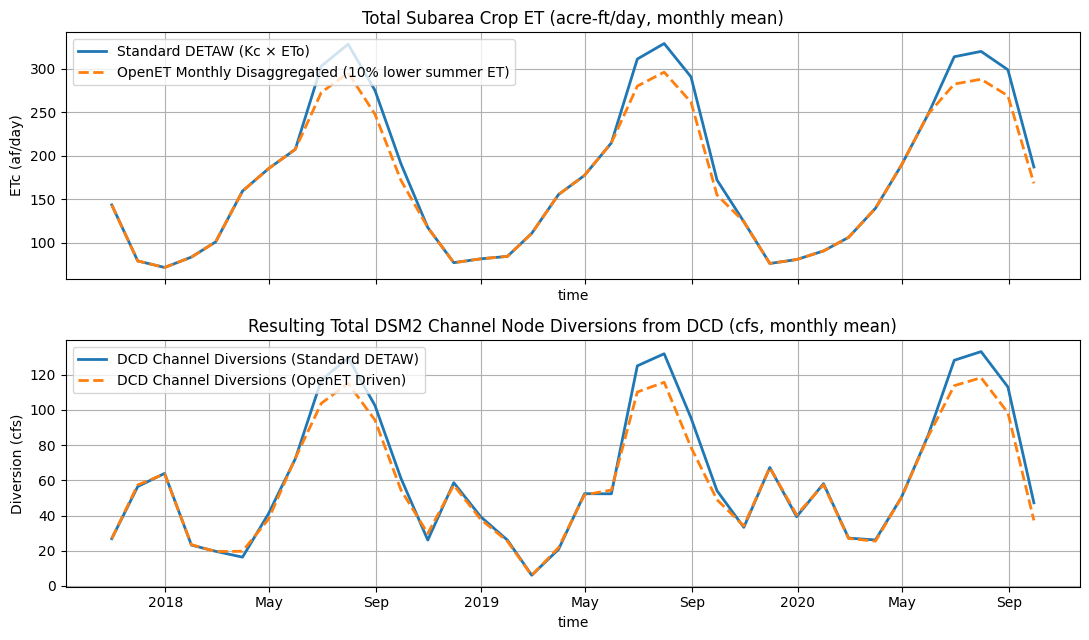

In [3]:
with tempfile.TemporaryDirectory() as tmpdir:
    tmp = Path(tmpdir)

    # 1. Run standard internal Kc * ETo DETAW on examples/detaw_ex1.yaml for WY 2018-2020
    cfg_std = DetawConfig.from_yaml(REPO_ROOT / "examples" / "detaw_ex1.yaml")
    cfg_std.start_water_year = 2018
    cfg_std.end_water_year = 2020
    std_nc = tmp / "detaw_standard.nc"
    cfg_std.detaw_output_path = str(std_nc)
    cfg_std.precip_output_path = None
    cfg_std.et_output_path = None
    ds_std = DetawModel(cfg_std).run(write_outputs=True)

    # 2. Construct a synthetic monthly OpenET dataset (e.g., 10% lower summer crop ET due to deficit irrigation)
    cfg_std_mm = DetawConfig.from_yaml(REPO_ROOT / "examples" / "detaw_ex1.yaml")
    cfg_std_mm.start_water_year = 2018
    cfg_std_mm.end_water_year = 2020
    cfg_std_mm.daily_output_unit = 0  # mm/day
    ds_mm = DetawModel(cfg_std_mm).run(write_outputs=False)

    monthly_etc = ds_mm["et_c"].resample(time="MS").sum()
    summer_mask = monthly_etc["time"].dt.month.isin([6, 7, 8, 9])
    openet_monthly = xr.where(summer_mask, monthly_etc * 0.90, monthly_etc).transpose(
        "time", "subarea", "crop"
    )
    openet_nc = tmp / "openet_monthly_mm.nc"
    xr.Dataset({"openet_etc": openet_monthly}).to_netcdf(openet_nc)

    # 3. Configure DETAW to use OpenET monthly NetCDF and run DETAW -> DCD!
    cfg_openet = DetawConfig.from_yaml(REPO_ROOT / "examples" / "detaw_ex1.yaml")
    cfg_openet.start_water_year = 2018
    cfg_openet.end_water_year = 2020
    cfg_openet.et.provider = "openet"
    cfg_openet.et.external_path = str(openet_nc)
    cfg_openet.et.external_variable = "openet_etc"
    cfg_openet.et.external_units = "mm/month"
    cfg_openet.et.temporal_resolution = "monthly"
    cfg_openet.et.disaggregation = "et0_scaled"
    openet_detaw_nc = tmp / "detaw_openet.nc"
    cfg_openet.detaw_output_path = str(openet_detaw_nc)
    cfg_openet.precip_output_path = None
    cfg_openet.et_output_path = None
    ds_openet = DetawModel(cfg_openet).run(write_outputs=True)

    # 4. Run DCD on both standard DETAW and OpenET-driven DETAW outputs
    with open(REPO_ROOT / "examples" / "dcd_ex1.yaml") as f:
        dcd_base = yaml.safe_load(f)["dcd"]
    for k, v in list(dcd_base.items()):
        if k.startswith("path_") and v is not None:
            dcd_base[k] = str((REPO_ROOT / "examples" / v).resolve())
    dcd_base["start_water_year"] = 2018
    dcd_base["end_water_year"] = 2020

    for tag, det_nc in [("std", std_nc), ("openet", openet_detaw_nc)]:
        d_cfg = dict(
            dcd_base,
            path_detaw_output=str(det_nc),
            path_dcd_output=str(tmp / f"dcd_areas_{tag}.nc"),
            path_dcd_node_output=str(tmp / f"dcd_nodes_{tag}.nc"),
        )
        y_path = tmp / f"dcd_{tag}.yaml"
        y_path.write_text(yaml.safe_dump({"dcd": d_cfg}))
        deltacd.dcd.dcd(str(y_path))

    dcd_std = xr.open_dataset(tmp / "dcd_nodes_std.nc").load()
    dcd_oet = xr.open_dataset(tmp / "dcd_nodes_openet.nc").load()

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
ds_std["et_c"].sum(dim=("subarea", "crop")).resample(time="ME").mean().plot(
    ax=axes[0], label="Standard DETAW (Kc × ETo)", lw=2.0
)
ds_openet["et_c"].sum(dim=("subarea", "crop")).resample(time="ME").mean().plot(
    ax=axes[0], label="OpenET Monthly Disaggregated (10% lower summer ET)", lw=2.0, ls="--"
)
axes[0].set_title("Total Subarea Crop ET (acre-ft/day, monthly mean)")
axes[0].set_ylabel("ETc (af/day)")
axes[0].legend()

dcd_std["diversion"].sum(dim="node").resample(time="ME").mean().plot(
    ax=axes[1], label="DCD Channel Diversions (Standard DETAW)", lw=2.0
)
dcd_oet["diversion"].sum(dim="node").resample(time="ME").mean().plot(
    ax=axes[1], label="DCD Channel Diversions (OpenET Driven)", lw=2.0, ls="--"
)
axes[1].set_title("Resulting Total DSM2 Channel Node Diversions from DCD (cfs, monthly mean)")
axes[1].set_ylabel("Diversion (cfs)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. Order-Independent CSV Inputs & Custom Crop Categories

All readers in `deltacd.detaw.io` resolve headers, row labels, stations, subareas, and crop codes dynamically. Below we shuffle the column and row order of `landuse_ex1.csv` and verify that `read_landuse` produces an identical dataset.

In [4]:
from deltacd.detaw import read_landuse

orig_lu = read_landuse(
    REPO_ROOT / "examples" / "inputs" / "landuse_ex1.csv", water_years=[2020, 2021]
)

with tempfile.TemporaryDirectory() as tmpdir:
    df = pd.read_csv(REPO_ROOT / "examples" / "inputs" / "landuse_ex1.csv")
    rng = np.random.default_rng(123)
    df_shuffled = df.loc[rng.permutation(df.index), rng.permutation(list(df.columns))]
    print("Shuffled first 6 CSV columns:", list(df_shuffled.columns[:6]))
    shuf_path = Path(tmpdir) / "shuffled_landuse.csv"
    df_shuffled.to_csv(shuf_path, index=False)

    shuf_lu = read_landuse(shuf_path, water_years=[2020, 2021]).sel(crop=orig_lu["crop"])
    xr.testing.assert_identical(orig_lu, shuf_lu)
    print("Success: Shuffled CSV produced bit-for-bit identical xarray.Dataset!")

Shuffled first 6 CSV columns: ['RI', 'PA', 'NV', 'WS', 'TO', 'DGR']
Success: Shuffled CSV produced bit-for-bit identical xarray.Dataset!
